# Example: Calculate Delta, Theta, Vega, Rho, and Gamma for Short and Long Options Contracts
In the lecture, we estimated each Greek by repricing an option on a binomial tree with one input moved up and down. How close do these estimates come to the Greeks quoted in the market?

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Compute and interpret the five key Greeks for American options:__ Calculate Delta, Theta, Vega, Rho, and Gamma for a call and a put on the Leisen–Reimer tree, and explain what each one measures.
> * __Compare Greek values between calls and puts:__ Explain how the signs and sizes of the Greeks differ between a long call and a long put, and what each sign means for the holder.
> * __Convert Greeks between long and short positions:__ Use the fact that long and short Greeks sum to zero to find the seller's Greeks. Use the Greeks of one contract to size a Delta hedge and estimate its change in price.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, and loads the functions in the local `src` directory. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
Let's load an end-of-day options chain from the course archive (31 tickers, captured after each close from April 13 to October 16, 2026). [The `MyOptionsEODChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsEODChainDataSet) returns the chain for one ticker, trading session, and expiration, with that session's share price. 

[The `filter(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#Base.filter) keeps the expiration matched to `target_dte`, and we store the results in the `metadata::Dict{String,Any}` and `optionschain::DataFrame` variables.

In [2]:
ticker = "NVDA"; # underlying ticker: any of the 31 tickers in the archive
quote_date = Date(2026, 10, 8); # trading session of the quotes
target_dte = 45; # days to expiration target, one of the archive's ladder values (2, 7, 14, 30, 45)

metadata, optionschain = let

    # initialize: the first call downloads the archive (about 112 MB) -
    session = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date); # every expiration that session

    # keep the expiration matched to the target -
    expiration = filter(:target_dte => ==(target_dte), session.data).expiration |> first;
    options_dataset = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date, expiration = expiration);
    metadata = options_dataset.metadata;
    optionschain = options_dataset.data;

    (metadata, optionschain) # return
end;

What about the `optionschain` variable? [The `select(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#DataFrames.select) keeps the columns we use. The archive quotes each contract's Greeks: `theta` is per calendar day, and `vega` and `rho` are per percentage point.

In [3]:
select(optionschain, :type, :strike, :bid, :ask, :mid, :implied_vol, :delta, :gamma, :theta, :vega, :rho) # the columns we use; the chain has 19

Row,type,strike,bid,ask,mid,implied_vol,delta,gamma,theta,vega,rho
,String,Float64,Float64,Float64,Float64,Float64?,Float64?,Float64?,Float64?,Float64?,Float64?
1,call,2.5,223.85,234.5,229.175,missing,missing,missing,missing,missing,missing
2,call,5.0,221.32,225.24,223.28,missing,missing,missing,missing,missing,missing
3,call,7.5,220.34,227.43,223.885,missing,missing,missing,missing,missing,missing
4,call,10.0,219.59,226.54,223.065,missing,missing,missing,missing,missing,missing
5,call,12.5,211.46,223.19,217.325,missing,missing,missing,missing,missing,missing
6,call,15.0,211.59,219.98,215.785,missing,missing,missing,missing,missing,missing
7,call,17.5,212.29,215.81,214.05,missing,missing,missing,missing,missing,missing
8,call,20.0,206.22,216.42,211.32,missing,missing,missing,missing,missing,missing
9,call,22.5,207.09,215.73,211.41,missing,missing,missing,missing,missing,missing


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, permissible values, etc. 

In [4]:
Sₒ = metadata["underlying_close"]; # share price at the close of the quote date (USD/share)
DTE = metadata["DTE"]; # days to expiration (days)
day = (1/365); # one day, expressed in years
T = DTE*day; # time to expiration (years)
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-08 (0.0418 on 2026-10-16), U.S. Treasury Daily Treasury Bill Rates (accessed 2026-10-19); update it if you change quote_date
# https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_bill_rates&field_tdr_date_value_month=202610
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)
h = 20*DTE + 1; # number of levels of the tree: about twenty per day, odd for the Leisen–Reimer tree
ε_σ = 0.01; # volatility step: one percentage point (1/sqrt(yr))
ε_g = 0.01; # risk-free rate step: one percentage point (1/yr)
ε_t = day; # calendar time step: one day (yr)
ε_S = 0.01*Sₒ; # share price step: 1% of Sₒ (USD/share)

Let's collect (and display) these inputs in one table with [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table):

In [5]:
let
    # the inputs every repricing in this notebook shares -
    df = DataFrame(
        quantity = ["quote date", "expiration", "days to expiration", "share price Sₒ", "time to expiration T",
            "risk-free rate gᵧ", "tree levels h", "volatility step ε_σ", "rate step ε_g", "time step ε_t", "share price step ε_S"],
        value    = Any[metadata["quote_date"], metadata["expiration_date"], DTE, Sₒ, round(T, digits = 4),
            round(gᵧ, digits = 4), h, ε_σ, ε_g, round(ε_t, digits = 5), round(ε_S, digits = 4)],
        units    = ["", "", "days", "USD/share", "years", "1/year", "levels", "1/sqrt(year)", "1/year", "years", "USD/share"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        fit_table_in_display_horizontally = false, table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ---------------------- ------------ --------------
  quantity                    value   units        
 ---------------------- ------------ --------------
  quote date             2026-10-08
  expiration             2026-11-20
  days to expiration             43   days
  share price Sₒ             230.57   USD/share
  time to expiration T       0.1178   years
  risk-free rate gᵧ          0.0413   1/year
  tree levels h                 861   levels
  volatility step ε_σ          0.01   1/sqrt(year)
  rate step ε_g                0.01   1/year
  time step ε_t             0.00274   years
  share price step ε_S       2.3057   USD/share
 ---------------------- ------------ --------------


### Contract models
Next, we select the call and the put whose strike price is nearest the share price, among contracts with an implied volatility and quoted Greeks. [The `argmin(...)` function](https://docs.julialang.org/en/v1/base/collections/#Base.argmin) finds that strike, and the mid price is the premium. We store the two rows in the `call_row::DataFrameRow` and `put_row::DataFrameRow` variables:

In [6]:
call_row, put_row = let

    # keep the contracts with an implied volatility and quoted Greeks -
    usable = filter(row -> !ismissing(row[:implied_vol]) && !ismissing(row[:delta]), optionschain);
    calls = filter(row -> row[:type] == "call", usable); # usable call contracts, i.e., those with an implied volatility and quoted Greeks
    puts = filter(row -> row[:type] == "put", usable); # usable put contracts, i.e., those with an implied volatility and quoted Greeks

    # the strike nearest the share price -
    call_row = calls[argmin(abs.(calls.strike .- Sₒ)), :]; # the row of the call contract nearest the share price
    put_row = puts[argmin(abs.(puts.strike .- Sₒ)), :]; # the row of the put contract nearest the share price

    (call_row, put_row) # return
end;

DataFrame([call_row, put_row]) |> x -> select(x, :type, :strike, :bid, :ask, :mid, :implied_vol, :delta, :gamma, :theta, :vega, :rho)

Row,type,strike,bid,ask,mid,implied_vol,delta,gamma,theta,vega,rho
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,call,230.0,12.02,12.28,12.15,0.3521,0.5538,0.0142,-0.1407,0.3135,0.1364
2,put,230.0,10.56,10.71,10.635,0.37,-0.4464,0.0135,-0.1227,0.3135,-0.134


We build the call's contract model, an instance of [the `MyAmericanCallContractModel` type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanCallContractModel), with [the `build(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}). 

Its [NamedTuple](https://docs.julialang.org/en/v1/base/base/#Core.NamedTuple) argument sets the strike price, the premium, the time to expiration in years (the `DTE` field), the position (`sense = 1`, long), the number of contracts (`copy`), and the implied volatility. We save the model in the `call_option_model::MyAmericanCallContractModel` variable:

In [7]:
call_option_model = build(MyAmericanCallContractModel, (
    K = call_row.strike, # strike price (USD/share)
    premium = call_row.mid, # mid price (USD/share)
    DTE = T, # time to expiration (years)
    sense = 1, # long, we always compute long and convert to short if needed
    copy = 1, # one contract, i.e., controls 100 shares
    IV = call_row.implied_vol # implied volatility (1/sqrt(yr))
));

We build the put the same way, as an instance of [the `MyAmericanPutContractModel` type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanPutContractModel), and save it in the `put_option_model::MyAmericanPutContractModel` variable:

In [8]:
put_option_model = build(MyAmericanPutContractModel, (
    K = put_row.strike, # strike price (USD/share)
    premium = put_row.mid, # mid price (USD/share)
    DTE = T, # time to expiration (years)
    sense = 1, # long, we always compute long and convert to short if needed
    copy = 1, # one contract, i.e., controls 100 shares
    IV = put_row.implied_vol 
));

### Repricing on the Leisen–Reimer tree
Every Greek in this example is a central difference of repriced premiums. [The `binomial_premium(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.binomial_premium) prices a call or put on a tree with `h` levels, at full precision, and `method = :leisen_reimer` selects the Leisen–Reimer tree. [The `𝒫(...)` function](src/Helper.jl) wraps it and takes all five inputs, so we can move one and hold the others fixed.

[The `show_value(...)` function](src/Helper.jl) shows a computed value with its units, and [the `compare_greek(...)` function](src/Helper.jl) shows a computed Greek next to the archive's quote.

___

## Task 1: Compute the Greeks for a Long Call Option
In this task, we'll compute the five Greeks of the long call on the Leisen–Reimer tree and compare each one with the archive's quote. Let's start with Delta.

### Delta Long Call
Delta measures the change in the premium $\mathcal{P}_{c}$ for a `+1 USD/share` change in the share price. We move the share price up and down by the step $\epsilon_{S}$ and reprice the call:
$$
\Delta_{c}\approx\frac{\mathcal{P}_{c}(S_{o}+\epsilon_{S})-\mathcal{P}_{c}(S_{o}-\epsilon_{S})}{2\epsilon_{S}}
$$
We store the estimate in the `delta_long_call::Float64` variable. So what do we get?

In [9]:
delta_long_call = let

    # initialize -
    model = call_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice with the share price moved up and down by ε_S -
    𝒫_up = 𝒫(model; S = Sₒ + ε_S, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)
    𝒫_down = 𝒫(model; S = Sₒ - ε_S, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)

    # central difference -
    (𝒫_up - 𝒫_down)/(2*ε_S)
end

0.5481063229085609

__Summary__: For a long call, $\Delta_{c}\geq{0}$, so the premium $\mathcal{P}_{c}$ rises with the share price. That is why a long call can stand in for owning shares.

> __Hedging Interpretation:__
>
> Delta gives the number of shares one contract is equivalent to, $n_{c}$ shares per contract:
> $$
> \begin{align*}
> n_{c} &= 100\cdot\Delta_{c}
> \end{align*}
> $$
> where $\Delta_{c}$ is the Delta of a long call contract.

Thus, this long call contract is equivalent to:

In [10]:
show_value("share equivalents, one long call", 100*delta_long_call, "shares per contract")

 ---------------------------------- ------- ---------------------
  quantity                           value   units               
 ---------------------------------- ------- ---------------------
  share equivalents, one long call   54.81   shares per contract
 ---------------------------------- ------- ---------------------


#### Check: How good is our delta estimate?
The archive quotes a Delta for this contract, computed by the data provider with its own model and inputs. Let's compare it with ours using [the `@assert` macro](https://docs.julialang.org/en/v1/base/base/#Base.@assert) and [the `isapprox(...)` function](https://docs.julialang.org/en/v1/base/math/#Base.isapprox).

> __Test:__ [The `isapprox(...)` function](https://docs.julialang.org/en/v1/base/math/#Base.isapprox) returns `true` when two values agree within the relative tolerance `rtol`. If it returns `false`, an [AssertionError](https://docs.julialang.org/en/v1/base/base/#Core.AssertionError) is thrown. We ask for agreement within 10% of the quoted value, which also requires the same sign.

So what do we find?

In [11]:
let
    quoted = call_row.delta; # Delta quoted in the archive
    compare_greek("Delta", delta_long_call, quoted, "1");

    # checks: within 10% of the quote, and the sign is correct -
    @assert isapprox(delta_long_call, quoted, rtol = 0.10)
end

 ---------------------- --------- -------
  quantity                 value   units 
 ---------------------- --------- -------
  Delta, Leisen–Reimer    0.5481   1
  Delta, archive quote    0.5538   1
  difference             -0.0057   1
 ---------------------- --------- -------


### Theta Long Call
Theta measures the change in the premium $\mathcal{P}_{c}$ as calendar time passes. Moving the calendar time forward by $\epsilon_{t}$ shortens the time to expiration $T$ by $\epsilon_{t}$, so we reprice the call with $T$ moved down and up:
$$
\Theta_{c}\approx\frac{\mathcal{P}_{c}(T-\epsilon_{t})-\mathcal{P}_{c}(T+\epsilon_{t})}{2\epsilon_{t}}
$$
We store the estimate, in USD/share per year, in the `theta_long_call::Float64` variable. What is our time decay estimate?

In [12]:
theta_long_call = let

    # initialize -
    model = call_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice with calendar time moved forward and back by ε_t: forward means less time to expiration -
    𝒫_forward = 𝒫(model; S = Sₒ, σ = σ, T = T - ε_t, g = gᵧ, h = h); # (USD/share)
    𝒫_back = 𝒫(model; S = Sₒ, σ = σ, T = T + ε_t, g = gᵧ, h = h); # (USD/share)

    # central difference -
    (𝒫_forward - 𝒫_back)/(2*ε_t)
end

-51.56461742497356

__Summary__: For a long call, $\Theta_{c}<0$, so with all else fixed, the premium falls as expiration approaches. This loss is the time decay. For one call contract, the time decay is:

In [13]:
show_value("time decay, one long call", 100*theta_long_call/365, "USD per day per contract")

 --------------------------- -------- --------------------------
  quantity                     value   units                    
 --------------------------- -------- --------------------------
  time decay, one long call   -14.13   USD per day per contract
 --------------------------- -------- --------------------------


#### Check: How good is our theta estimate?
The archive quotes Theta per day, so we compare our estimate divided by 365. So what happens?

In [14]:
let
    computed = theta_long_call/365; # USD/share per day
    quoted = call_row.theta; # Theta quoted in the archive (USD/share per day)
    compare_greek("Theta", computed, quoted, "USD/share per day");

    # checks: within 10% of the quote, and the sign is correct -
    @assert isapprox(computed, quoted, rtol = 0.10)
end

 ---------------------- --------- -------------------
  quantity                 value   units             
 ---------------------- --------- -------------------
  Theta, Leisen–Reimer   -0.1413   USD/share per day
  Theta, archive quote   -0.1407   USD/share per day
  difference             -0.0006   USD/share per day
 ---------------------- --------- -------------------


### Vega Long Call
Vega measures the change in the premium $\mathcal{P}_{c}$ for a change in the implied volatility. We move the volatility up and down by $\epsilon_{\sigma}$, one percentage point, and reprice the call:
$$
\nu_{c}\approx\frac{\mathcal{P}_{c}(\sigma+\epsilon_{\sigma})-\mathcal{P}_{c}(\sigma-\epsilon_{\sigma})}{2\epsilon_{\sigma}}
$$
We store the estimate in the `vega_long_call::Float64` variable. So what is our volatility sensitivity estimate?

In [15]:
vega_long_call = let

    # initialize -
    model = call_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice with the volatility moved up and down by ε_σ -
    𝒫_up = 𝒫(model; S = Sₒ, σ = σ + ε_σ, T = T, g = gᵧ, h = h); # (USD/share)
    𝒫_down = 𝒫(model; S = Sₒ, σ = σ - ε_σ, T = T, g = gᵧ, h = h); # (USD/share)

    # central difference -
    (𝒫_up - 𝒫_down)/(2*ε_σ)
end

31.340968538902203

__Summary__: For the long call, $\nu_{c}>0$, so the premium rises with the implied volatility. More uncertainty in the future share price makes the option more expensive, because the seller demands more compensation for the added risk.

#### Check: How good is our vega estimate?
The archive quotes Vega per percentage point, so we compare our estimate divided by 100. So did we pass the test?

In [16]:
let
    computed = vega_long_call/100; # USD/share per percentage point
    quoted = call_row.vega; # Vega quoted in the archive (USD/share per percentage point)
    compare_greek("Vega", computed, quoted, "USD/share per point");

    # checks: within 10% of the quote, and the sign is correct -
    @assert isapprox(computed, quoted, rtol = 0.10)
end

 --------------------- --------- ---------------------
  quantity                value   units               
 --------------------- --------- ---------------------
  Vega, Leisen–Reimer    0.3134   USD/share per point
  Vega, archive quote    0.3135   USD/share per point
  difference            -0.0001   USD/share per point
 --------------------- --------- ---------------------


### Rho Long Call
Rho measures the change in the premium $\mathcal{P}_{c}$ for a change in the risk-free rate $g_{y}$. We move the rate up and down by $\epsilon_{g}$, one percentage point, and reprice the call:
$$
\rho_{c}\approx\frac{\mathcal{P}_{c}(g_{y}+\epsilon_{g})-\mathcal{P}_{c}(g_{y}-\epsilon_{g})}{2\epsilon_{g}}
$$
We store the estimate in the `rho_long_call::Float64` variable. So what is our interest rate sensitivity estimate?

In [17]:
rho_long_call = let

    # initialize -
    model = call_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice with the risk-free rate moved up and down by ε_g -
    𝒫_up = 𝒫(model; S = Sₒ, σ = σ, T = T, g = gᵧ + ε_g, h = h); # (USD/share)
    𝒫_down = 𝒫(model; S = Sₒ, σ = σ, T = T, g = gᵧ - ε_g, h = h); # (USD/share)

    # central difference -
    (𝒫_up - 𝒫_down)/(2*ε_g)
end

13.485421374463513

__Summary__: For a long call, $\rho_{c}>0$, so the premium rises with the risk-free rate. The rate usually changes little, but when rates rise, for example in inflationary periods, call premiums rise, all else being equal. For one call contract, a one-percentage-point rise in $g_{y}$ changes the value by:

In [18]:
show_value("change for a 1 point rise in gᵧ, one long call", 100*rho_long_call/100, "USD per contract")

 ------------------------------------------------ ------- ------------------
  quantity                                         value   units            
 ------------------------------------------------ ------- ------------------
  change for a 1 point rise in gᵧ, one long call   13.49   USD per contract
 ------------------------------------------------ ------- ------------------


#### Check: How good is our rho estimate?
The archive quotes Rho per percentage point, so we compare our estimate divided by 100. So what happens?

In [19]:
let
    computed = rho_long_call/100; # USD/share per percentage point
    quoted = call_row.rho; # Rho quoted in the archive (USD/share per percentage point)
    compare_greek("Rho", computed, quoted, "USD/share per point");

    # checks: within 10% of the quote, and the sign is correct -
    @assert isapprox(computed, quoted, rtol = 0.10)
end

 -------------------- --------- ---------------------
  quantity               value   units               
 -------------------- --------- ---------------------
  Rho, Leisen–Reimer    0.1349   USD/share per point
  Rho, archive quote    0.1364   USD/share per point
  difference           -0.0015   USD/share per point
 -------------------- --------- ---------------------


### Gamma Long Call
Gamma, the last Greek we'll explore, measures the change in Delta for a `+1 USD/share` change in the share price. We reprice the call at the two share prices we used for Delta, and at $S_{o}$:
$$
\Gamma_{c}\approx\frac{\mathcal{P}_{c}(S_{o}+\epsilon_{S})-2\,\mathcal{P}_{c}(S_{o})+\mathcal{P}_{c}(S_{o}-\epsilon_{S})}{\epsilon_{S}^{2}}
$$
We store the estimate in the `gamma_long_call::Float64` variable. What is our curvature estimate?

In [20]:
gamma_long_call = let

    # initialize -
    model = call_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice at the share price moved up, unchanged, and moved down by ε_S -
    𝒫_up = 𝒫(model; S = Sₒ + ε_S, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)
    𝒫_mid = 𝒫(model; S = Sₒ, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)
    𝒫_down = 𝒫(model; S = Sₒ - ε_S, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)

    # central second difference -
    (𝒫_up - 2*𝒫_mid + 𝒫_down)/(ε_S^2)
end

0.014204966269353093

__Summary__: The long call has $\Gamma_{c}>0$, so its Delta rises as the share price rises. A larger Gamma means Delta changes faster.

#### Check: How good is our gamma estimate?
So do we pass the test?

In [21]:
let
    quoted = call_row.gamma; # Gamma quoted in the archive (1/(USD/share))
    compare_greek("Gamma", gamma_long_call, quoted, "1/(USD/share)");

    # checks: within 10% of the quote, and the sign is correct -
    @assert isapprox(gamma_long_call, quoted, rtol = 0.10)
end

 ---------------------- -------- ---------------
  quantity                value   units         
 ---------------------- -------- ---------------
  Gamma, Leisen–Reimer   0.0142   1/(USD/share)
  Gamma, archive quote   0.0142   1/(USD/share)
  difference             0.0000   1/(USD/share)
 ---------------------- -------- ---------------


### Check: Do the Greeks stop changing?
Before we use these Greeks, we recompute them with $2h+1$ levels, still odd, and every step $\epsilon$ halved. [The `binomial_greeks(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.binomial_greeks) repeats our five central differences with the levels and steps we pass. Let's compare the two sets in the archive's units and ask that each change by less than 0.5%:

In [22]:
let

    # initialize: twice as many levels (still odd), and every step halved -
    model = call_option_model; # alias the contract model
    h₂ = 2*h + 1; # tree levels
    greeks = binomial_greeks(model; method = :leisen_reimer, h = h₂, T = T, σ = model.IV, Sₒ = Sₒ, μ = gᵧ,
        spot_bump = ε_S/2, volatility_bump = ε_σ/2, rate_bump = ε_g/2, time_bump = ε_t/2);

    # both estimates and the quotes, in the units of the archive's quotes -
    ours = [delta_long_call, gamma_long_call, theta_long_call/365, vega_long_call/100, rho_long_call/100];
    refined = [greeks.delta, greeks.gamma, greeks.theta/365, greeks.vega/100, greeks.rho/100];
    quoted = [call_row.delta, call_row.gamma, call_row.theta, call_row.vega, call_row.rho];

    # display -
    df = DataFrame(greek = ["Delta", "Gamma", "Theta", "Vega", "Rho"], ours = ours, refined = refined, quoted = quoted,
        units = ["1", "1/(USD/share)", "USD/share per day", "USD/share per point", "USD/share per point"]);
    pretty_table(df; column_labels = ["greek", "h = $(h)", "h = $(h₂), steps halved", "archive quote", "units"],
        alignment = [:l, :r, :r, :r, :l], formatters = [fmt__printf("%.4f", [2, 3, 4])], fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the Greeks change by less than 0.5% -
    @assert all(isapprox.(refined, ours, rtol = 0.005)) "a Greek changed by 0.5% or more"
end

 ------- --------- ------------------------ --------------- ---------------------
  greek   h = 861   h = 1723, steps halved   archive quote   units               
 ------- --------- ------------------------ --------------- ---------------------
  Delta    0.5481                   0.5482          0.5538   1
  Gamma    0.0142                   0.0142          0.0142   1/(USD/share)
  Theta   -0.1413                  -0.1413         -0.1407   USD/share per day
  Vega     0.3134                   0.3134          0.3135   USD/share per point
  Rho      0.1349                   0.1349          0.1364   USD/share per point
 ------- --------- ------------------------ --------------- ---------------------


___

## Task 2: Compute the Greeks for a Long Put Option
In this task, we'll compute the five Greeks of the long put and compare them with the archive's quotes and the long call. Then we'll look at how the Greeks change with the strike price and the time to expiration. Let's begin with Delta.

### Delta Long Put
We estimate Delta as for the call, now with the `put_option_model` instance, and store it in the `delta_long_put::Float64` variable:

In [23]:
delta_long_put = let

    # initialize -
    model = put_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice with the share price moved up and down by ε_S -
    𝒫_up = 𝒫(model; S = Sₒ + ε_S, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)
    𝒫_down = 𝒫(model; S = Sₒ - ε_S, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)

    # central difference -
    (𝒫_up - 𝒫_down)/(2*ε_S)
end

-0.45599403101185254

__Summary__: For the long put, $\Delta_{p}<0$, the opposite sign of the call, so the put's value falls as the share price rises. A buyer purchases a put when they expect the share price to fall.

> __What about the number of share equivalents?__
> For a long put, the number of share equivalents $n_{p}$ is negative, because the put acts like a short position in the shares.
>
> The number of share equivalents is:
> $$
> n_{p} = 100\cdot\Delta_{p}
> $$
> where $\Delta_{p}$ is the Delta of a long put contract.

Thus, this long put contract is equivalent to:

In [24]:
show_value("share equivalents, one long put", 100*delta_long_put, "shares per contract")

 --------------------------------- -------- ---------------------
  quantity                           value   units               
 --------------------------------- -------- ---------------------
  share equivalents, one long put   -45.60   shares per contract
 --------------------------------- -------- ---------------------


#### Check: How good is our delta estimate?
Is our estimate accurate?

In [25]:
let
    quoted = put_row.delta; # Delta quoted in the archive
    compare_greek("Delta", delta_long_put, quoted, "1");

    # checks: within 10% of the quote, and the sign is correct -
    @assert isapprox(delta_long_put, quoted, rtol = 0.10)
end

 ---------------------- --------- -------
  quantity                 value   units 
 ---------------------- --------- -------
  Delta, Leisen–Reimer   -0.4560   1
  Delta, archive quote   -0.4464   1
  difference             -0.0096   1
 ---------------------- --------- -------


### Theta Long Put
We estimate Theta as for the call, now with the `put_option_model` instance, and store it in the `theta_long_put::Float64` variable:

In [26]:
theta_long_put = let

    # initialize -
    model = put_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice with calendar time moved forward and back by ε_t: forward means less time to expiration -
    𝒫_forward = 𝒫(model; S = Sₒ, σ = σ, T = T - ε_t, g = gᵧ, h = h); # (USD/share)
    𝒫_back = 𝒫(model; S = Sₒ, σ = σ, T = T + ε_t, g = gᵧ, h = h); # (USD/share)

    # central difference -
    (𝒫_forward - 𝒫_back)/(2*ε_t)
end

-45.19793930104185

__Summary__: For the long put, $\Theta_{p}<0$, the same sign as the call. With all else fixed, both lose value as expiration approaches. For one put contract, the time decay is:

In [27]:
show_value("time decay, one long put", 100*theta_long_put/365, "USD per day per contract")

 -------------------------- -------- --------------------------
  quantity                    value   units                    
 -------------------------- -------- --------------------------
  time decay, one long put   -12.38   USD per day per contract
 -------------------------- -------- --------------------------


#### Check: How good is our theta estimate?
So are we good?

In [28]:
let
    computed = theta_long_put/365; # USD/share per day
    quoted = put_row.theta; # Theta quoted in the archive (USD/share per day)
    compare_greek("Theta", computed, quoted, "USD/share per day");

    # checks: within 10% of the quote, and the sign is correct -
    @assert isapprox(computed, quoted, rtol = 0.10)
end

 ---------------------- --------- -------------------
  quantity                 value   units             
 ---------------------- --------- -------------------
  Theta, Leisen–Reimer   -0.1238   USD/share per day
  Theta, archive quote   -0.1227   USD/share per day
  difference             -0.0011   USD/share per day
 ---------------------- --------- -------------------


### Vega Long Put
We estimate Vega as for the call, now with the `put_option_model` instance, and store it in the `vega_long_put::Float64` variable:

In [29]:
vega_long_put = let

    # initialize -
    model = put_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice with the volatility moved up and down by ε_σ -
    𝒫_up = 𝒫(model; S = Sₒ, σ = σ + ε_σ, T = T, g = gᵧ, h = h); # (USD/share)
    𝒫_down = 𝒫(model; S = Sₒ, σ = σ - ε_σ, T = T, g = gᵧ, h = h); # (USD/share)

    # central difference -
    (𝒫_up - 𝒫_down)/(2*ε_σ)
end

31.323297360345137

__Summary__: For the long put, $\nu_{p}>0$, so like the call, its premium rises with the implied volatility. More uncertainty makes both calls and puts more expensive.

#### Check: How good is our vega estimate?
What do we find?

In [30]:
let
    computed = vega_long_put/100; # USD/share per percentage point
    quoted = put_row.vega; # Vega quoted in the archive (USD/share per percentage point)
    compare_greek("Vega", computed, quoted, "USD/share per point");

    # checks: within 10% of the quote, and the sign is correct -
    @assert isapprox(computed, quoted, rtol = 0.10)
end

 --------------------- --------- ---------------------
  quantity                value   units               
 --------------------- --------- ---------------------
  Vega, Leisen–Reimer    0.3132   USD/share per point
  Vega, archive quote    0.3135   USD/share per point
  difference            -0.0003   USD/share per point
 --------------------- --------- ---------------------


### Rho Long Put
We estimate Rho as for the call, now with the `put_option_model` instance, and store it in the `rho_long_put::Float64` variable:

In [31]:
rho_long_put = let

    # initialize -
    model = put_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice with the risk-free rate moved up and down by ε_g -
    𝒫_up = 𝒫(model; S = Sₒ, σ = σ, T = T, g = gᵧ + ε_g, h = h); # (USD/share)
    𝒫_down = 𝒫(model; S = Sₒ, σ = σ, T = T, g = gᵧ - ε_g, h = h); # (USD/share)

    # central difference -
    (𝒫_up - 𝒫_down)/(2*ε_g)
end

-11.400436034529271

__Summary__: For a long put, $\rho_{p}<0$, so the premium falls as the risk-free rate rises. When rates rise, for example in inflationary periods, put premiums fall, all else being equal. For one put contract, a one-percentage-point rise in $g_{y}$ changes the value by:

In [32]:
show_value("change for a 1 point rise in gᵧ, one long put", 100*rho_long_put/100, "USD per contract")

 ----------------------------------------------- -------- ------------------
  quantity                                         value   units            
 ----------------------------------------------- -------- ------------------
  change for a 1 point rise in gᵧ, one long put   -11.40   USD per contract
 ----------------------------------------------- -------- ------------------


#### Check: How good is our rho estimate?
Let's compare our American put's Rho with the quote and with the Rho of a European put on the same tree, an instance of [the `MyEuropeanPutContractModel` type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyEuropeanPutContractModel):

In [33]:
let

    # the same put, written as a European contract -
    european_model = build(MyEuropeanPutContractModel, (K = put_row.strike, premium = put_row.mid, DTE = T,
        sense = 1, copy = 1, IV = put_row.implied_vol));
    σ = european_model.IV; # implied volatility (1/sqrt(year))
    𝒫_up = 𝒫(european_model; S = Sₒ, σ = σ, T = T, g = gᵧ + ε_g, h = h); # (USD/share)
    𝒫_down = 𝒫(european_model; S = Sₒ, σ = σ, T = T, g = gᵧ - ε_g, h = h); # (USD/share)
    rho_european_put = (𝒫_up - 𝒫_down)/(2*ε_g);

    # display -
    quoted = put_row.rho; # Rho quoted in the archive (USD/share per percentage point)
    df = DataFrame(quantity = ["Rho, American put (Leisen–Reimer)", "Rho, European put (Leisen–Reimer)", "Rho, archive quote"],
        value = [rho_long_put/100, rho_european_put/100, quoted], units = fill("USD/share per point", 3));
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.4f", [2])], fit_table_in_display_horizontally = false, table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the quote is close to the European Rho, and early exercise makes the American Rho smaller in size -
    @assert isapprox(rho_european_put/100, quoted, rtol = 0.10) # within 10% of the quote, and the sign is correct!
    @assert abs(rho_long_put) < abs(rho_european_put)
end

 ----------------------------------- --------- ---------------------
  quantity                              value   units               
 ----------------------------------- --------- ---------------------
  Rho, American put (Leisen–Reimer)   -0.1140   USD/share per point
  Rho, European put (Leisen–Reimer)   -0.1354   USD/share per point
  Rho, archive quote                  -0.1340   USD/share per point
 ----------------------------------- --------- ---------------------


__Why is the American put's Rho smaller in size?__ A put holder who exercises sells the shares at the strike price. A higher risk-free rate lowers the present value of that cash, which is why $\rho_{p}<0$. The American holder can exercise early and collect the cash sooner, so the rate matters less. The quoted Rho is close to the European put's Rho.

### Gamma Long Put
Finally, we estimate Gamma as for the call, now with the `put_option_model` instance, and store it in the `gamma_long_put::Float64` variable:

In [34]:
gamma_long_put = let

    # initialize -
    model = put_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))

    # reprice at the share price moved up, unchanged, and moved down by ε_S -
    𝒫_up = 𝒫(model; S = Sₒ + ε_S, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)
    𝒫_mid = 𝒫(model; S = Sₒ, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)
    𝒫_down = 𝒫(model; S = Sₒ - ε_S, σ = σ, T = T, g = gᵧ, h = h); # (USD/share)

    # central second difference -
    (𝒫_up - 2*𝒫_mid + 𝒫_down)/(ε_S^2)
end

0.013728257494219553

__Summary__: The long put also has $\Gamma_{p}>0$, so its Delta rises toward zero as the share price rises. A larger Gamma means Delta changes faster.

#### Check: How good is our gamma estimate?
So do we pass the test?

In [35]:
let
    quoted = put_row.gamma; # Gamma quoted in the archive (1/(USD/share))
    compare_greek("Gamma", gamma_long_put, quoted, "1/(USD/share)");

    # checks: within 10% of the quote, and the sign is correct -
    @assert isapprox(gamma_long_put, quoted, rtol = 0.10)
end

 ---------------------- -------- ---------------
  quantity                value   units         
 ---------------------- -------- ---------------
  Gamma, Leisen–Reimer   0.0137   1/(USD/share)
  Gamma, archive quote   0.0135   1/(USD/share)
  difference             0.0002   1/(USD/share)
 ---------------------- -------- ---------------


### How do Delta and Gamma change with the moneyness?
Before we sweep the strike price with `binomial_greeks(...)`, let's confirm it reproduces our values with the same `h` and steps:

In [36]:
let
    for (model, ours) ∈ ((call_option_model, (delta_long_call, gamma_long_call, theta_long_call, vega_long_call, rho_long_call)),
                         (put_option_model, (delta_long_put, gamma_long_put, theta_long_put, vega_long_put, rho_long_put)))

        # the package's central differences, with our steps -
        greeks = binomial_greeks(model; method = :leisen_reimer, h = h, T = T, σ = model.IV, Sₒ = Sₒ, μ = gᵧ,
            spot_bump = ε_S, volatility_bump = ε_σ, rate_bump = ε_g, time_bump = ε_t);

        # checks: the same five numbers -
        @assert all(isapprox.(values(greeks), ours, rtol = 1e-10)) "binomial_greeks(...) differs from our central differences"
    end
end

Now let's compute Delta and Gamma for every contract with an implied volatility and quoted Greeks, each at its own implied volatility, and store them in the `greeks_by_strike_df::DataFrame` variable:

In [37]:
greeks_by_strike_df = let

    # initialize -
    usable = filter(row -> !ismissing(row[:implied_vol]) && !ismissing(row[:delta]), optionschain);
    greeks_by_strike_df = DataFrame();

    for row ∈ eachrow(usable)

        # build a long contract model for this row -
        contract_type = (row[:type] == "call") ? MyAmericanCallContractModel : MyAmericanPutContractModel;
        model = build(contract_type, (K = row[:strike], premium = row[:mid], DTE = T, sense = 1, copy = 1, IV = row[:implied_vol]));

        # compute the Greeks with the same steps -
        greeks = binomial_greeks(model; method = :leisen_reimer, h = h, T = T, σ = model.IV, Sₒ = Sₒ, μ = gᵧ,
            spot_bump = ε_S, volatility_bump = ε_σ, rate_bump = ε_g, time_bump = ε_t);

        push!(greeks_by_strike_df, (type = row[:type], K = row[:strike], delta = greeks.delta, delta_quote = row[:delta],
            gamma = greeks.gamma, gamma_quote = row[:gamma]));
    end

    greeks_by_strike_df # return
end;

Let's plot the computed Delta and Gamma against the moneyness $K/S(0)$, the strike price divided by the share price, with [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot), [the `scatter!(...)` function](https://docs.juliaplots.org/stable/api/#Plots.scatter!-Tuple), and [the `vline!(...)` function](https://docs.juliaplots.org/stable/api/#Plots.vline!-Tuple), with the archive's quotes as points:

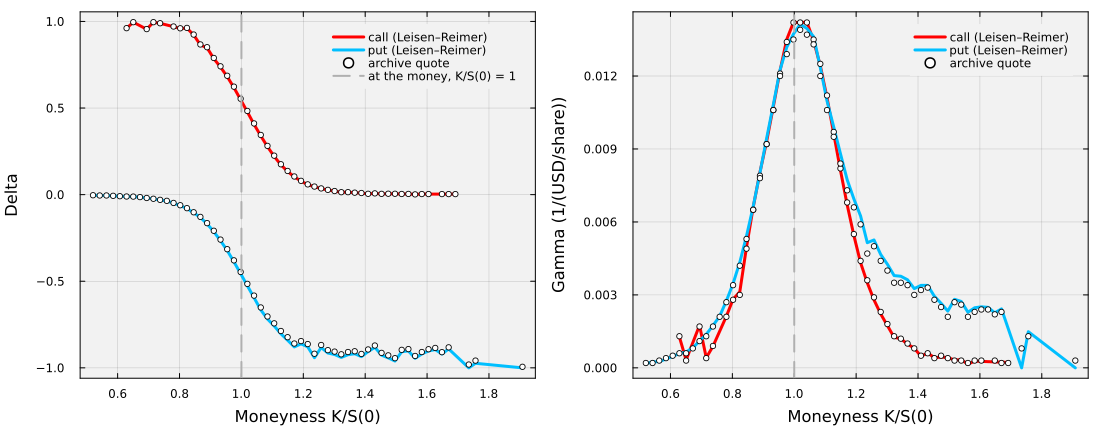

In [38]:
let
    # initialize -
    calls = filter(row -> row[:type] == "call", greeks_by_strike_df);
    puts = filter(row -> row[:type] == "put", greeks_by_strike_df);
    m_calls = calls.K ./ Sₒ; # moneyness K/S(0) of the calls (dimensionless)
    m_puts = puts.K ./ Sₒ; # moneyness K/S(0) of the puts (dimensionless)

    # Delta against the moneyness -
    p1 = plot(m_calls, calls.delta, lw = 3, c = :red, label = "call (Leisen–Reimer)");
    plot!(p1, m_puts, puts.delta, lw = 3, c = :deepskyblue1, label = "put (Leisen–Reimer)");
    scatter!(p1, vcat(m_calls, m_puts), vcat(calls.delta_quote, puts.delta_quote), c = :white, ms = 3, label = "archive quote");
    vline!(p1, [1.0], lw = 2, c = :gray69, ls = :dash, label = "at the money, K/S(0) = 1");
    xlabel!(p1, "Moneyness K/S(0)"); ylabel!(p1, "Delta");

    # Gamma against the moneyness -
    p2 = plot(m_calls, calls.gamma, lw = 3, c = :red, label = "call (Leisen–Reimer)");
    plot!(p2, m_puts, puts.gamma, lw = 3, c = :deepskyblue1, label = "put (Leisen–Reimer)");
    scatter!(p2, vcat(m_calls, m_puts), vcat(calls.gamma_quote, puts.gamma_quote), c = :white, ms = 3, label = "archive quote");
    vline!(p2, [1.0], lw = 2, c = :gray69, ls = :dash, label = "");
    xlabel!(p2, "Moneyness K/S(0)"); ylabel!(p2, "Gamma (1/(USD/share))");

    plot(p1, p2, layout = (1, 2), size = (1100, 430), bg = "gray95", background_color_outside = "white",
        framestyle = :box, fg_legend = :transparent, left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
end

### How do the Greeks change with time to expiration?
For each shorter expiration listed on the quote date, let's take the call whose strike price is nearest the share price and compute its Gamma, Theta, and Vega. Each tree has an odd number of levels, about twenty per day and at least 201, and the time step is at most a quarter of the time to expiration:

In [39]:
let

    # initialize: every expiration on the quote date -
    session = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date).data;
    df = DataFrame();

    for expiration ∈ sort(unique(session.expiration))

        # the call nearest the money for this expiration -
        calls = filter(row -> row[:expiration] == expiration && row[:type] == "call" &&
            !ismissing(row[:implied_vol]) && !ismissing(row[:delta]), session);
        nrow(calls) == 0 && continue;
        row = calls[argmin(abs.(calls.strike .- Sₒ)), :];

        # tree and steps for this expiration -
        Tₑ = row[:dte]*day; # time to expiration (years)
        hₑ = max(20*row[:dte], 200) + 1; # tree levels: about twenty per day, at least 201, odd
        σ = row[:implied_vol];
        model = build(MyAmericanCallContractModel, (K = row[:strike], premium = row[:mid], DTE = Tₑ, sense = 1, copy = 1, IV = σ));
        greeks = binomial_greeks(model; method = :leisen_reimer, h = hₑ, T = Tₑ, σ = σ, Sₒ = Sₒ, μ = gᵧ,
            spot_bump = ε_S, volatility_bump = ε_σ, rate_bump = ε_g, time_bump = min(ε_t, Tₑ/4));

        push!(df, (DTE = row[:dte], K = row[:strike], gamma = greeks.gamma, gamma_quote = row[:gamma],
            theta = greeks.theta/365, theta_quote = row[:theta], vega = greeks.vega/100, vega_quote = row[:vega]));
    end

    # display -
    pretty_table(df; column_labels = ["DTE (days)", "K (USD/share)", "Gamma", "Gamma quote", "Theta/day", "Theta quote",
        "Vega/point", "Vega quote"], formatters = [fmt__printf("%.4f", [3, 4, 5, 6, 7, 8])],
        fit_table_in_display_vertically = false, fit_table_in_display_horizontally = false, table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the signs the lecture describes for a long call -
    @assert all(df.gamma .> 0.0) && all(df.theta .< 0.0) && all(df.vega .> 0.0)
end

 ------------ --------------- -------- ------------- ----------- ------------- ------------ ------------
  DTE (days)   K (USD/share)    Gamma   Gamma quote   Theta/day   Theta quote   Vega/point   Vega quote 
 ------------ --------------- -------- ------------- ----------- ------------- ------------ ------------
           1           230.0   0.0990        0.0991     -0.7813       -0.7580       0.0475       0.0464
           4           230.0   0.0657        0.0655     -0.3110       -0.3055       0.0955       0.0946
           6           230.0   0.0482        0.0480     -0.2853       -0.2826       0.1173       0.1167
           8           230.0   0.0378        0.0377     -0.2739       -0.2722       0.1355       0.1351
          11           230.0   0.0362        0.0361     -0.2109       -0.2097       0.1589       0.1584
          13           230.0   0.0313        0.0312     -0.2068       -0.2058       0.1727       0.1724
          15           230.0   0.0280        0.0279     -0.20

### Discussion
* Gamma is largest for strikes near the share price. Why does an option deep in or far out of the money have a Gamma near zero?
* As the expiration date approaches, how do the Gamma, Theta, and Vega of the call nearest the money change? What does that mean for the buyer of a short-dated option?
___

## Task 3: Convert the Greeks to Short Contracts and Positions
In this task, we'll convert the long Greeks to short contracts, then use them to describe one contract's exposure, size its Delta hedge, and estimate its change in price. The long and short Greeks of the same contract sum to zero.

> __Greeks for Short Contracts__
>
> Denote a short Greek by an overbar, so $\bar{\Delta}_{c}$ is the Delta of a short call.
>
> In every market state:
> $$
> \begin{align*}
> \bar{\Delta}_{c} + \Delta_{c} = 0
> \end{align*}
> $$

The same holds for every Greek. Let's build a table of the long and short call's Greeks, in the units of the archive's quotes:

In [40]:
let

    # initialize -
    sense = -1; # short
    long = [delta_long_call, gamma_long_call, theta_long_call/365, vega_long_call/100, rho_long_call/100];
    quoted = [call_row.delta, call_row.gamma, call_row.theta, call_row.vega, call_row.rho];

    # display -
    df = DataFrame(greek = ["Delta", "Gamma", "Theta (per day)", "Vega (per point)", "Rho (per point)"],
        long = long, short = sense .* long, check = long .+ sense .* long, quoted = quoted);
    pretty_table(df; column_labels = ["greek", "long call", "short call", "long + short", "archive quote (long)"],
        alignment = [:l, :r, :r, :r, :r], formatters = [fmt__printf("%.4f", [2, 3, 4, 5])],
        fit_table_in_display_horizontally = false, table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ------------------ ----------- ------------ -------------- ----------------------
  greek              long call   short call   long + short   archive quote (long) 
 ------------------ ----------- ------------ -------------- ----------------------
  Delta                 0.5481      -0.5481         0.0000                 0.5538
  Gamma                 0.0142      -0.0142         0.0000                 0.0142
  Theta (per day)      -0.1413       0.1413         0.0000                -0.1407
  Vega (per point)      0.3134      -0.3134         0.0000                 0.3135
  Rho (per point)       0.1349      -0.1349         0.0000                 0.1364
 ------------------ ----------- ------------ -------------- ----------------------


and the put contract:

In [41]:
let

    # initialize -
    sense = -1; # short
    long = [delta_long_put, gamma_long_put, theta_long_put/365, vega_long_put/100, rho_long_put/100];
    quoted = [put_row.delta, put_row.gamma, put_row.theta, put_row.vega, put_row.rho];

    # display -
    df = DataFrame(greek = ["Delta", "Gamma", "Theta (per day)", "Vega (per point)", "Rho (per point)"],
        long = long, short = sense .* long, check = long .+ sense .* long, quoted = quoted);
    pretty_table(df; column_labels = ["greek", "long put", "short put", "long + short", "archive quote (long)"],
        alignment = [:l, :r, :r, :r, :r], formatters = [fmt__printf("%.4f", [2, 3, 4, 5])],
        fit_table_in_display_horizontally = false, table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ------------------ ---------- ----------- -------------- ----------------------
  greek              long put   short put   long + short   archive quote (long) 
 ------------------ ---------- ----------- -------------- ----------------------
  Delta               -0.4560      0.4560         0.0000                -0.4464
  Gamma                0.0137     -0.0137         0.0000                 0.0135
  Theta (per day)     -0.1238      0.1238         0.0000                -0.1227
  Vega (per point)     0.3132     -0.3132         0.0000                 0.3135
  Rho (per point)     -0.1140      0.1140         0.0000                -0.1340
 ------------------ ---------- ----------- -------------- ----------------------


### What does one contract expose us to?
Each contract covers 100 shares. For a signed number of contracts $n$, with $n<0$ for a short position, the lecture's Delta hedge is $-100\cdot n\cdot\Delta$ shares. Let's compute the exposure of one contract for each of the four positions:

In [42]:
let

    # initialize -
    positions = [
        ("long call", 1, delta_long_call, gamma_long_call, theta_long_call, vega_long_call, rho_long_call),
        ("short call", -1, delta_long_call, gamma_long_call, theta_long_call, vega_long_call, rho_long_call),
        ("long put", 1, delta_long_put, gamma_long_put, theta_long_put, vega_long_put, rho_long_put),
        ("short put", -1, delta_long_put, gamma_long_put, theta_long_put, vega_long_put, rho_long_put)
    ];

    # one contract: 100 shares times the signed contract count -
    exposure(n, Δ, Γ, Θ, ν, ρ) = [100*n*Δ, -100*n*Δ, 100*n*Γ, 100*n*Θ/365, 100*n*ν/100, 100*n*ρ/100];
    columns = [exposure(n, Δ, Γ, Θ, ν, ρ) for (_, n, Δ, Γ, Θ, ν, ρ) ∈ positions];
    df = DataFrame(quantity = ["share equivalents", "Delta hedge", "Gamma", "Theta", "Vega", "Rho"]);
    for (i, position) ∈ enumerate(positions)
        df[!, position[1]] = columns[i];
    end
    df[!, "units"] = ["shares", "shares", "shares per USD/share", "USD per day", "USD per point", "USD per point"];

    # display -
    pretty_table(df; column_labels = names(df), alignment = [:l, :r, :r, :r, :r, :l], formatters = [fmt__printf("%.2f", [2, 3, 4, 5])],
        fit_table_in_display_horizontally = false, table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: each hedge cancels its position's Delta -
    @assert all(isapprox.(Vector(df[1, 2:5]) .+ Vector(df[2, 2:5]), 0.0, atol = 1e-10))
end

 ------------------- ----------- ------------ ---------- ----------- ----------------------
  quantity            long call   short call   long put   short put   units                
 ------------------- ----------- ------------ ---------- ----------- ----------------------
  share equivalents       54.81       -54.81     -45.60       45.60   shares
  Delta hedge            -54.81        54.81      45.60      -45.60   shares
  Gamma                    1.42        -1.42       1.37       -1.37   shares per USD/share
  Theta                  -14.13        14.13     -12.38       12.38   USD per day
  Vega                    31.34       -31.34      31.32      -31.32   USD per point
  Rho                     13.49       -13.49     -11.40       11.40   USD per point
 ------------------- ----------- ------------ ---------- ----------- ----------------------


### How good is the local price-change estimate?
When only the share price moves, the lecture's expansion estimates the change in the call premium from Delta and Gamma:
$$
\Delta\mathcal{P}_{c}\approx\Delta_{c}\,\Delta S+\frac{1}{2}\,\Gamma_{c}\,(\Delta S)^{2}
$$
Let's move the share price by 2.5% and 5% each way and compare the Delta-only and Delta–Gamma estimates with full repricing on the tree, for one long call contract. The last column adds the Delta hedge of $-100\cdot\Delta_{c}$ shares:

In [43]:
let

    # initialize -
    model = call_option_model; # alias the contract model
    σ = model.IV; # implied volatility (1/sqrt(year))
    base = 𝒫(model; S = Sₒ, σ = σ, T = T, g = gᵧ, h = h); # premium today (USD/share)
    moves = Sₒ .* [-0.05, -0.025, 0.025, 0.05]; # share price changes ΔS (USD/share)
    df = DataFrame();

    for ΔS ∈ moves
        delta_only = 100*delta_long_call*ΔS; # USD per contract
        delta_gamma = 100*(delta_long_call*ΔS + 0.5*gamma_long_call*ΔS^2); # USD per contract
        full = 100*(𝒫(model; S = Sₒ + ΔS, σ = σ, T = T, g = gᵧ, h = h) - base); # USD per contract
        hedged = full - 100*delta_long_call*ΔS; # long call plus the Delta hedge (USD)
        push!(df, (ΔS = ΔS, delta_only = delta_only, delta_gamma = delta_gamma, full = full, hedged = hedged));
    end

    # display -
    pretty_table(df; column_labels = ["ΔS (USD/share)", "Delta only (USD)", "Delta–Gamma (USD)", "full repricing (USD)",
        "hedged position (USD)"], formatters = [fmt__printf("%.2f", [1, 2, 3, 4, 5])],
        fit_table_in_display_horizontally = false, table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: adding Gamma improves the estimate, and the hedged long call gains in both directions -
    @assert all(abs.(df.delta_gamma .- df.full) .< abs.(df.delta_only .- df.full))
    @assert all(df.hedged .> 0.0)
end

 ---------------- ------------------ ------------------- ---------------------- -----------------------
  ΔS (USD/share)   Delta only (USD)   Delta–Gamma (USD)   full repricing (USD)   hedged position (USD) 
 ---------------- ------------------ ------------------- ---------------------- -----------------------
          -11.53            -631.88             -537.49                -535.74                   96.14
           -5.76            -315.94             -292.34                -292.08                   23.86
            5.76             315.94              339.54                 339.15                   23.21
           11.53             631.88              726.28                 722.20                   90.32
 ---------------- ------------------ ------------------- ---------------------- -----------------------


__Why does the hedged position gain in both directions?__ The hedge cancels the Delta term, so the change that remains is close to the Gamma term $\frac{1}{2}\Gamma_{c}(\Delta S)^{2}$. For a long call, that term is positive whichever way the share price moves. The hedged position still loses value to Theta as time passes.

___

## Summary
In this example, we computed and interpreted the five Greeks of an American call and put on the Leisen–Reimer tree and converted them between long and short positions. We also compared the Greeks with the archive's quotes across strikes and expirations, then sized a Delta hedge and estimated a contract's price change.

> __Key Takeaways:__
>
> * __Greeks quantify option price sensitivity:__ Delta, Theta, Vega, and Rho measure how the premium responds to the share price, time, volatility, and the risk-free rate, and Gamma measures how fast Delta changes. Our tree estimates agreed closely with the archive's quotes, except the American put's Rho, which early exercise makes smaller in size.
> * __Call and put Greeks have different signs:__ A long call has a positive Delta and Rho, and a long put has a negative Delta and Rho. Both lose value as time passes and gain when the implied volatility rises.
> * __Long and short Greeks sum to zero:__ The seller's Greeks are the buyer's with the sign flipped. Multiplied by 100 shares per contract, the Greeks size a Delta hedge, and Delta and Gamma together estimate a contract's price change for small share price moves.

Together, the Greeks tell us how a position's value moves with the share price, time, volatility, and rates, and how many shares hedge it.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___